# Solar PV Forecasting with a Time-Series Foundation Model

 **A compact, reproducible zero-shot forecasting benchmark using Amazon Chronos-Bolt-Tiny.**

 ## TL;DR

 | Evaluation | Seasonal Naive MAE | Chronos MAE | Non-negative Chronos MAE | Best vs. Naive |
 |---|---:|---:|---:|---:|
 | 7 daily forecasts | 1.9338 kW | 1.5968 kW | **1.5699 kW** | **18.82% lower** |
 | 30 daily forecasts | 3.3604 kW | 2.6122 kW | **2.5896 kW** | **22.94% lower** |

 **Research question:** Can a general-purpose time-series foundation model improve short-term PV power forecasts *without task-specific fine-tuning*, and does a simple non-negativity constraint help?

 Reported results and figures below were retained from the supplied executed notebook. The input CSV is fetched from its public source when cells are rerun.

## 1. Context, method, and assumptions

 - **Data:** [PV-Generation-Dataset, Site A](https://github.com/upb-nlp/PV-Generation-Dataset), hourly AC active power (`active_power_kw`). Dataset authors: Linca, Rebedea, Ruseti & Dascalu (2026), licensed CC BY 4.0.
 - **Model:** [`amazon/chronos-bolt-tiny`](https://huggingface.co/amazon/chronos-bolt-tiny), used in zero-shot inference mode (no gradient updates, no fine-tuning).
 - **Context / horizon:** 14 days (336 hourly observations) → next 24 hours.
 - **Baseline:** seasonal naive, i.e., repeat the previous day's hourly generation profile.
 - **Constraint:** clip negative power forecasts to zero using `np.maximum(prediction, 0)`. This is **physics-constrained output post-processing**, not a physics-informed training objective.
 - **Evaluation:** walk-forward / rolling-origin daily forecasting. After each 24-hour evaluation, the real observed day becomes available for the next prediction. All forecasts are strictly forward in time.
 - **Metric:** mean absolute error (MAE), in kW; smaller is better.

 The 7-day and 30-day evaluations use **different but overlapping calendar windows** ending on the dataset's final day. Their average errors should not be interpreted as estimates on independent test sets. These are small demonstrative tests, not evidence of generalization across sites/seasons.

 ### Install dependencies

 From the repository directory:

 ```bash
 pip install -r requirements.txt
 ```

 Model weights and source data are downloaded when the notebook first runs. CPU inference is used.

## 2. Imports and public PV data

In [17]:
import numpy as np
import pandas as pd
import torch
from chronos import BaseChronosPipeline

In [18]:
url = (
    "https://raw.githubusercontent.com/upb-nlp/"
    "PV-Generation-Dataset/main/site_a/"
    "site_a_hourly_weather.csv"
)

In [19]:
df = pd.read_csv(url, parse_dates=["datetime_local"])
df = df.sort_values("datetime_local")
df = df.drop_duplicates("datetime_local")

### Input checks

 Use hourly timestamps and check that the selected evaluation window contains no missing hours. Dataset readings are local-time timestamps as supplied by the repository.

## 3. Seven-day zero-shot evaluation

In [21]:
y = (df.set_index("datetime_local")["active_power_kw"]
       .asfreq("h").tail(21 * 24))

In [22]:
assert y.notna().all(), "Check missing hours"
values = y.to_numpy(dtype=np.float32)

### Load the pretrained Chronos-Bolt-Tiny model (CPU)

In [23]:
model = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-tiny",
    device_map="cpu"
)

### Generate seven 24-hour forecasts with a 336-hour context window

In [24]:
results = []

for t in range(14 * 24, 21 * 24, 24):
    context = values[t-336:t]
    actual = values[t:t+24]

    naive = context[-24:]

    forecast = model.predict(
        torch.from_numpy(context),
        prediction_length=24
    )

    fm = forecast[0, 4].cpu().numpy()
    fm_physics = np.maximum(fm, 0)

    mae = lambda p: np.mean(np.abs(actual - p))
    results.append([mae(naive), mae(fm), mae(fm_physics)])


In [25]:
print(pd.DataFrame(
    results,
    columns=["Naive", "Chronos", "Physics-Chronos"]
).mean())

Naive              1.933752
Chronos            1.596760
Physics-Chronos    1.569889
dtype: float32


**Result:** Chronos reduces MAE by **17.43%** relative to seasonal naive. Non-negative post-processing reduces it by **18.82%** relative to seasonal naive (and **1.68%** relative to raw Chronos).

### Last forecast day: actual vs. predicted power

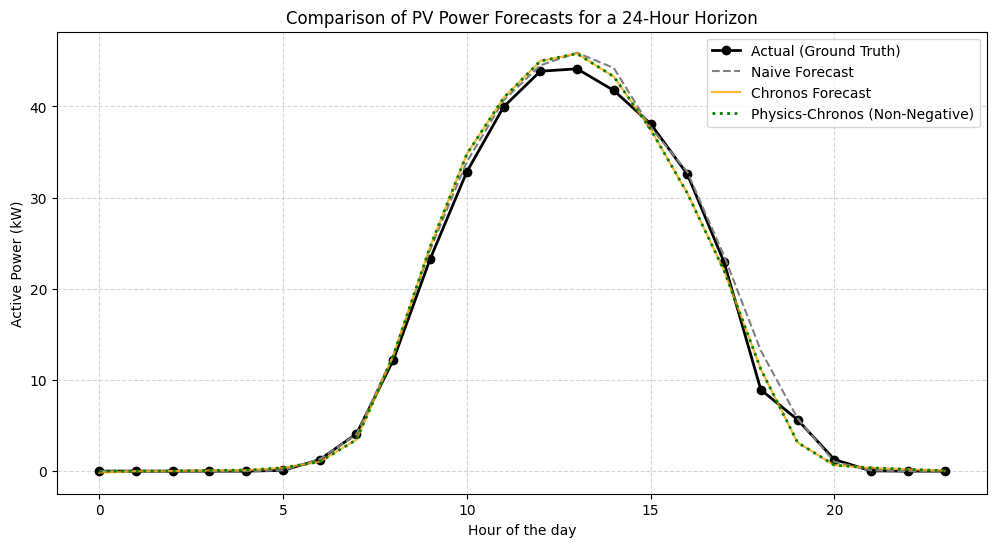

In [26]:
import matplotlib.pyplot as plt

# Let's visualize the final forecasted day
plt.figure(figsize=(12, 6))
hours = np.arange(24)

plt.plot(hours, actual, label='Actual (Ground Truth)', color='black', linewidth=2, marker='o')
plt.plot(hours, naive, label='Naive Forecast', color='gray', linestyle='--')
plt.plot(hours, fm, label='Chronos Forecast', color='orange', alpha=0.8)
plt.plot(hours, fm_physics, label='Physics-Chronos (Non-Negative)', color='green', linestyle=':', linewidth=2)

plt.title('Comparison of PV Power Forecasts for a 24-Hour Horizon')
plt.xlabel('Hour of the day')
plt.ylabel('Active Power (kW)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

## 4. Thirty-day rolling-origin evaluation

 **Important:** This is *not* one continuous 720-hour-ahead forecast. It is **30 separate day-ahead (24-hour) forecasts**, each using the preceding 14 days of **observed** power. The results are scored against each day's actual values. Model weights stay frozen.

In [27]:
# ==========================================
# 30-Day Rolling-Origin Evaluation
# ==========================================

# 14 days of context + 30 days of testing
context_days = 14
test_days = 30

total_hours = (context_days + test_days) * 24

y30 = (
    df.set_index("datetime_local")["active_power_kw"]
    .asfreq("h")
    .tail(total_hours)
)

assert len(y30) == total_hours, "Not enough data"
assert y30.notna().all(), "Missing hourly values"

values30 = y30.to_numpy(dtype=np.float32)

results30 = []

for t in range(
    context_days * 24,
    total_hours,
    24
):
    # Previous 14 days
    context = values30[t - 336:t]

    # Next 24 hours
    actual = values30[t:t + 24]

    # Seasonal Naive
    naive = context[-24:]

    # Chronos Zero-Shot Forecast
    forecast = model.predict(
        torch.from_numpy(context),
        prediction_length=24
    )

    fm = forecast[0, 4].cpu().numpy()

    # Physics-Constrained Forecast
    fm_physics = np.maximum(fm, 0)

    # Calculate MAE
    mae = lambda p: np.mean(np.abs(actual - p))

    results30.append({
        "Date": y30.index[t].date(),
        "Naive": mae(naive),
        "Chronos": mae(fm),
        "Physics-Chronos": mae(fm_physics)
    })

# Results
results30_df = pd.DataFrame(results30)

mean_mae30 = results30_df[
    ["Naive", "Chronos", "Physics-Chronos"]
].mean()

print("=== 30-Day Evaluation Results ===")
print(mean_mae30)

# Improvement percentages
naive_mae = mean_mae30["Naive"]
chronos_mae = mean_mae30["Chronos"]
physics_mae = mean_mae30["Physics-Chronos"]

print("\n=== Improvements ===")

print(
    "Chronos vs Naive:",
    round((naive_mae - chronos_mae) / naive_mae * 100, 2),
    "%"
)

print(
    "Physics-Chronos vs Naive:",
    round((naive_mae - physics_mae) / naive_mae * 100, 2),
    "%"
)

print(
    "Physics vs Chronos:",
    round((chronos_mae - physics_mae) / chronos_mae * 100, 2),
    "%"
)

=== 30-Day Evaluation Results ===
Naive              3.360425
Chronos            2.612219
Physics-Chronos    2.589578
dtype: float32

=== Improvements ===
Chronos vs Naive: 22.27 %
Physics-Chronos vs Naive: 22.94 %
Physics vs Chronos: 0.87 %


**Result:** In the 30-day window, Chronos MAE is **2.6122 kW** and constrained Chronos MAE is **2.5896 kW**, vs. seasonal naive **3.3604 kW**. This corresponds to **22.94% lower MAE** than the naive baseline.

 The difference between the 7-day and 30-day errors reflects differing dates and conditions; it does **not** by itself establish a trend in model quality.

### Daily MAE across the 30 forecast dates

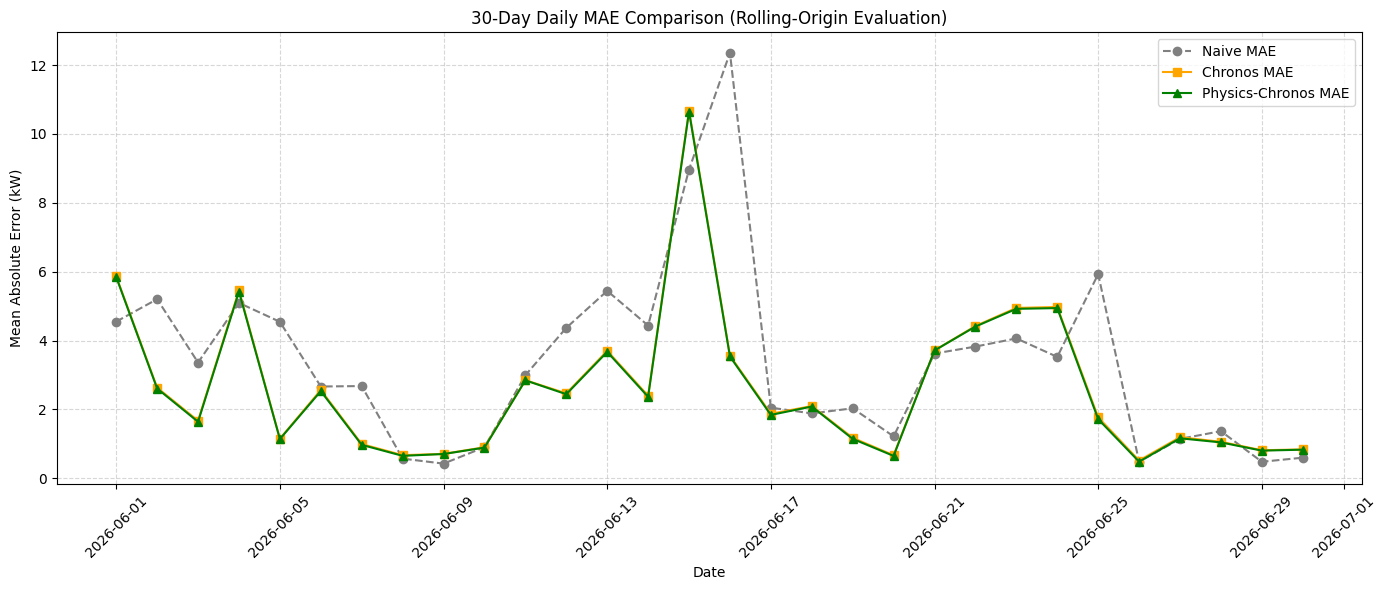

In [29]:

plt.figure(figsize=(14, 6))
plt.plot(results30_df["Date"], results30_df["Naive"], label="Naive MAE", color="gray", linestyle="--", marker="o")
plt.plot(results30_df["Date"], results30_df["Chronos"], label="Chronos MAE", color="orange", marker="s")
plt.plot(results30_df["Date"], results30_df["Physics-Chronos"], label="Physics-Chronos MAE", color="green", marker="^")

plt.title("30-Day Daily MAE Comparison (Rolling-Origin Evaluation)")
plt.xlabel("Date")
plt.ylabel("Mean Absolute Error (kW)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Interpretation and limitations

 1. **Transfer without fine-tuning:** On these windows, Chronos-Bolt-Tiny outperforms seasonal naive, demonstrating a useful zero-shot baseline for this *one* PV dataset.
 2. **Physical plausibility:** Clipping negative predictions is a safe post-processing rule **for a non-negative target**. It should not be confused with learning a physical law, and it does not guarantee nighttime zeros or compliance with inverter capacity.
 3. **Single-site, short-window evidence:** This analysis does not establish robustness under seasonality changes, different PV sites, cloud regimes or outages. The broad model's pretraining data composition is not audited for source overlap.
 4. **No exogenous features:** Although weather data exist in the dataset, this experiment uses **only historical power**; future weather forecasts, time-of-day features, and solar position are not given to the model.
 5. **MAE scope:** Scores are calculated over every hour, including nighttime, which can make overall errors look smaller than daytime-only errors.

 ### Next steps

 Evaluate multiple seasons and Site B; report daylight-only MAE, model latency, and a weather-aware baseline; add confidence intervals over test days.

 ### Provenance

 The numerical outputs and two figures shown in this notebook are from the original executed notebook supplied with this project. Other than markdown organization and removing an oversized raw data display, the evaluation code and numerical outputs have not been changed. A fresh run is needed to test reproducibility against the current public CSV and locally installed dependencies.